# Page orientation: visual validation
## tl;dr
Run all cells to inspect successful corrections, a real confident mistake, and abstentions.
The saved outputs below are from the actual CPU classifier, with no mocked predictions.
**This is a deliberately small demonstration, not an estimate of production accuracy.**

The saved examples show correct agreement/public-page corrections and confident 180°
reversals on sparse signatory pages. Low-confidence reviews leave input orientation unchanged.
Use the per-document tables below rather than treating these selected cases as a benchmark.

## Context & Methods
Use `uv sync --locked --group notebook`, then `uv run --group notebook jupyter lab`.
Run from the repository root. Model weights download once; the two public example images are bundled.

### Key Assumptions
- Ground truth is the known **counterclockwise (CCW) rotation** of an upright reference.
  Expected model label = `(-CCW) % 360`; correction uses the predicted label CCW.
- One CPU model is reused. Full pages are rasterized at 125 DPI, honoring PDF `/Rotate`;
  the pipeline caps inference input at 1600 px. No text regions are selected.
- Threshold **0.6**: lower scores retain the displayed input. A review is not a successful
  automatic correction; an initially upright retained page can still be upright.
- Five timed passes visit all pages in seeded random order **after warm-up**. Reported
  inference milliseconds come from `orient_pdf.predict`: model preprocessing, execution,
  and postprocessing, excluding rasterization, input thumbnailing, plotting, and PDF writing.
- Repeated timings and rotated copies are correlated. Two public pages do not constitute
  an independent orientation benchmark. Sparse layouts were deliberately chosen to expose failure.

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from time import perf_counter
import hashlib, io, json, os, platform
import fitz
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import orient_pdf as op
from test_orient import sample_pdf, font

ROOT = Path.cwd()
assert (ROOT / "orient_pdf.py").exists(), "Start Jupyter from the repository root"
DATA = ROOT / "validation_data"
DATA.mkdir(exist_ok=True)
THRESHOLD, REPEATS, INCLUDE_PUBLIC = 0.6, 5, True
plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"Python {platform.python_version()} | {platform.machine()} | CPU count {os.cpu_count()}")
print(f"Paddle CPU threads: {os.getenv('ORIENT_THREADS', '4')} | threshold {THRESHOLD}")

Python 3.13.5 | x86_64 | CPU count 3
Paddle CPU threads: 4 | threshold 0.6


## Data
Three synthetic PDF documents: a six-page agreement with accents and Chinese names (if the
font exists), a four-page sparse signatory register, and a four-page footer-only signatory
layout. All include known rotations. The sparse pages have readable upright names, giving
human reviewers an orientation reference even when handwriting dominates.

Optionally add two [DocLayNet](https://github.com/DS4SD/DocLayNet) pages, each at all four
rotations. Their original text was visually checked upright. These are 1025 × 1025 images
as supplied by the [DocLayNet-small mirror](https://huggingface.co/datasets/pierreguillou/DocLayNet-small),
not original-resolution scans, and contain no signature evaluation. Set `INCLUDE_PUBLIC=False`
to exclude them. See [data provenance and license](data/doclaynet/README.md).

In [2]:
def sparse_page(footer_only=False):
    page = Image.new("RGB", (1000, 1400), "white")
    draw = ImageDraw.Draw(page)
    draw.text((65, 70), "SIGNATURES / SIGNATURES DES PARTIES", font=font(20), fill="black")
    for i, name in enumerate(["Élodie García", "François Müller", "Anaïs López"]):
        y = 1050 + i * 85 if footer_only else 240 + i * 340
        draw.text((65, y), name, font=font(16), fill="black")
        points = [(400 + t * 5, y + 40 + int(13 * np.sin(t * .85))
                   + int(np.random.default_rng(i + t).integers(-8, 9))) for t in range(65)]
        draw.line(points, fill="#233e78", width=2)
        draw.line((400, y + 63, 840, y + 50), fill="#233e78", width=2)
    return page


def write_rotations(path, upright):
    with fitz.open() as pdf:
        for ccw, flag in zip((0, 90, 180, 270), (0, 90, 0, 270)):
            scan = upright.rotate((ccw + flag) % 360, expand=True)
            data = io.BytesIO()
            scan.save(data, format="PNG")
            page = pdf.new_page(width=scan.width * 72 / 125, height=scan.height * 72 / 125)
            page.insert_image(page.rect, stream=data.getvalue())
            page.set_rotation(flag)
        pdf.save(path, deflate=True)


documents = []
references = sample_pdf(DATA / "agreement.pdf")
documents.append(("Agreement", "synthetic", DATA / "agreement.pdf",
                  [image for _, image in references], [0, 90, 180, 270, 180, 0][:len(references)]))
for name, footer in [("Sparse register", False), ("Footer signatures", True)]:
    upright = sparse_page(footer)
    path = DATA / ("footer.pdf" if footer else "sparse.pdf")
    write_rotations(path, upright)
    documents.append((name, "synthetic", path, [upright] * 4, [0, 90, 180, 270]))

if INCLUDE_PUBLIC:
    source_dir = ROOT / "data/doclaynet"
    manifest = json.loads((source_dir / "manifest.json").read_text())
    for entry in manifest:
        source = source_dir / entry["file"]
        assert hashlib.sha256(source.read_bytes()).hexdigest() == entry["sha256"]
        upright = Image.open(source).convert("RGB")
        name = f"DocLayNet row {entry['row_index']}"
        path = DATA / f"doclaynet-{entry['row_index']}.pdf"
        write_rotations(path, upright)
        documents.append((name, "public", path, [upright] * 4, [0, 90, 180, 270]))

display(pd.DataFrame([{"Document": n, "Source": s, "Pages": len(r), "PDF": p.name}
                      for n, s, p, r, a in documents]))

,Document,Source,Pages,PDF
0,Agreement,synthetic,6,agreement.pdf
1,Sparse register,synthetic,4,sparse.pdf
2,Footer signatures,synthetic,4,footer.pdf
3,DocLayNet row 0,public,4,doclaynet-0.pdf
4,DocLayNet row 1,public,4,doclaynet-1.pdf


### Load once; use the actual pipeline
The corrected previews are returned by `orient_pages`. Timed repeat predictions must agree
with those pipeline decisions; no labels, confidence values, or failures are substituted.

In [3]:
started = perf_counter()
model = op.load_model()
load_ms = (perf_counter() - started) * 1000
with fitz.open(documents[0][2]) as pdf:
    warmup = op.rasterize(pdf[0])
for _ in range(3):
    op.predict(warmup, model)
print(f"Model setup: {load_ms:.0f} ms (excluded); three warm-up predictions excluded")

records, previews = [], {}
for name, source, path, originals, rotations in documents:
    with fitz.open(path) as pdf, redirect_stdout(io.StringIO()):
        for page_index, angle, confidence, corrected in op.orient_pages(pdf, model, THRESHOLD):
            key = len(records)
            ccw = rotations[page_index]
            accepted = confidence >= THRESHOLD
            residual = (ccw + (op.correction_angle(angle) if accepted else 0)) % 360
            records.append(dict(id=key, document=name, source=source, page=page_index,
                ccw=ccw, expected=(-ccw) % 360, predicted=angle, confidence=confidence,
                accepted=accepted, classifier_correct=angle == (-ccw) % 360,
                final_upright=residual == 0, residual=residual))
            previews[key] = (op.rasterize(pdf[page_index]), corrected, originals[page_index])
results = pd.DataFrame(records)

# Seeded interleaving avoids always timing the same document first.
timings = []
rng = np.random.default_rng(42)
for repeat in range(REPEATS):
    for key in rng.permutation(len(results)):
        row = results.loc[key]
        angle, confidence, scores, ms = op.predict(previews[key][0], model)
        assert angle == row.predicted and abs(confidence - row.confidence) < 1e-4
        timings.append(dict(document=row.document, id=int(key), repeat=repeat, ms=ms))
        if repeat == 0:
            results.loc[key, "p0"] = scores[0]
            results.loc[key, "p180"] = scores[180]
timing = pd.DataFrame(timings)
results["wrong_auto"] = results.accepted & ~results.final_upright
results["review"] = ~results.accepted
results.to_csv(DATA / "page_results.csv", index=False)
timing.to_csv(DATA / "inference_timings.csv", index=False)
print(f"Measured {len(results)} pages across {len(documents)} documents; {len(timing)} timed calls")

/workspace/document-image-orient/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model files already exist. Using cached files. To redownload, please delete the directory manually: `/workspace/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.


/workspace/document-image-orient/.venv/lib/python3.13/site-packages/paddle/utils/cpp_extension/extension_utils.py:712: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Model setup: 3570 ms (excluded); three warm-up predictions excluded


Measured 22 pages across 5 documents; 110 timed calls


## Results
### Accuracy and review workload by document
**Classifier accuracy** uses all pages, even abstentions. **Coverage** is the share accepted
for automatic correction. **Accepted accuracy** uses only accepted pages. **Final upright**
also counts unrotated, already-upright pages. **Wrong auto** counts incorrectly oriented
accepted outputs. Overall rates below are page-weighted, not averages of document rates.

,Pages,Classifier %,Coverage %,Accepted accuracy %,Final upright %,Reviews,Wrong auto
Agreement,6.0,100.0,100.0,100.0,100.0,0.0,0.0
Sparse register,4.0,50.0,100.0,50.0,50.0,0.0,2.0
Footer signatures,4.0,50.0,25.0,100.0,50.0,3.0,0.0
DocLayNet row 0,4.0,100.0,100.0,100.0,100.0,0.0,0.0
DocLayNet row 1,4.0,100.0,100.0,100.0,100.0,0.0,0.0
Overall,22.0,81.8,86.4,89.5,81.8,3.0,2.0


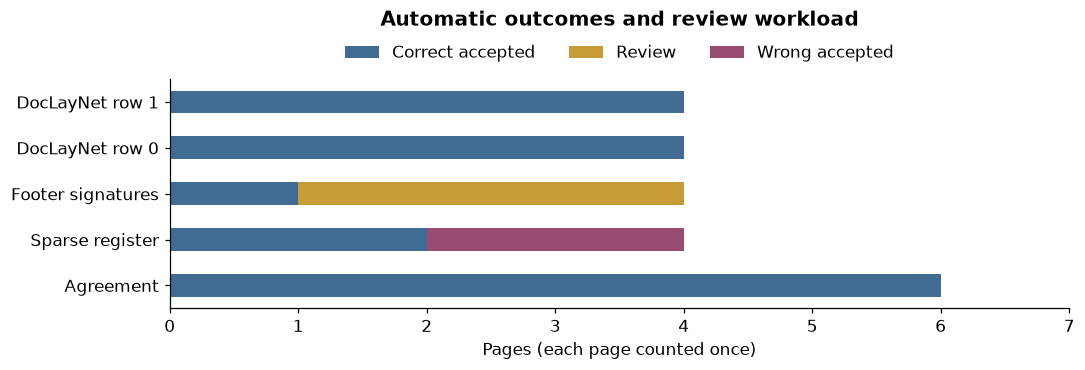

In [4]:
def summarize(frame):
    accepted = frame[frame.accepted]
    return pd.Series({"Pages": len(frame), "Classifier %": 100 * frame.classifier_correct.mean(),
        "Coverage %": 100 * frame.accepted.mean(),
        "Accepted accuracy %": 100 * accepted.final_upright.mean() if len(accepted) else np.nan,
        "Final upright %": 100 * frame.final_upright.mean(),
        "Reviews": int(frame.review.sum()), "Wrong auto": int(frame.wrong_auto.sum())})

summary = pd.DataFrame({name: summarize(group) for name, group in results.groupby("document", sort=False)}).T
summary.loc["Overall"] = summarize(results)
display(summary.round(1))
counts = pd.DataFrame({
    "Correct accepted": results.accepted & results.final_upright,
    "Review": results.review,
    "Wrong accepted": results.wrong_auto,
}).groupby(results.document, sort=False).sum()
ax = counts.plot.barh(stacked=True, figsize=(10, 3.5), color=["#406c94", "#c79b36", "#994c72"])
ax.set(xlabel="Pages (each page counted once)", ylabel="", title="Automatic outcomes and review workload")
ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.01), ncol=3, frameon=False)
ax.set_title("Automatic outcomes and review workload", pad=35)
ax.set_xlim(0, counts.sum(axis=1).max() + 1)
plt.tight_layout()
plt.show()

### Inference time statistics
Warm CPU inference only; each page is measured five times. P95 uses NumPy's linear
percentile interpolation. Standard deviation is the sample standard deviation. Timings
reflect this machine and this small repeated workload, not end-to-end service latency.

Boxes span the 25th–75th percentiles; the orange line is the median and the blue diamond
is the mean. Whiskers reach the most extreme observations within 1.5 box widths of each
quartile; circles mark observations beyond them. With few calls per document, tail values
are sensitive to CPU scheduling.

,Calls,Mean ms,Median ms,P95 ms,Std ms,Min ms,Max ms
DocLayNet row 0,20.0,52.76,45.67,108.01,35.85,7.01,125.55
Footer signatures,20.0,50.44,44.81,113.69,39.46,6.51,151.27
DocLayNet row 1,20.0,58.57,33.58,205.14,82.53,8.73,349.96
Sparse register,20.0,39.60,25.50,93.31,30.28,9.59,110.90
Agreement,30.0,41.26,24.98,115.43,35.19,7.93,119.59
Overall,110.0,47.87,36.74,115.43,47.15,6.51,349.96


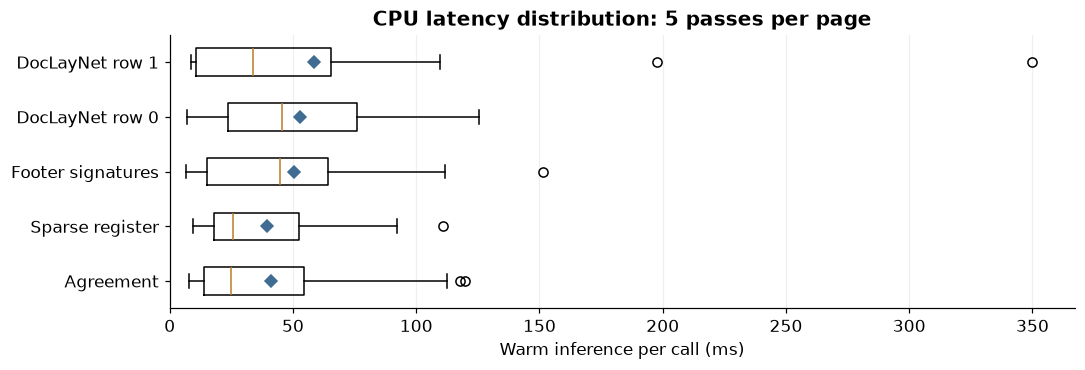

In [5]:
def latency_stats(frame):
    return pd.Series({"Calls": len(frame), "Mean ms": frame.ms.mean(), "Median ms": frame.ms.median(),
        "P95 ms": frame.ms.quantile(.95), "Std ms": frame.ms.std(ddof=1),
        "Min ms": frame.ms.min(), "Max ms": frame.ms.max()})
latencies = pd.DataFrame({name: latency_stats(group) for name, group in timing.groupby("document", sort=False)}).T
latencies.loc["Overall"] = latency_stats(timing)
display(latencies.round(2))
names = results.document.unique()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.boxplot([timing.loc[timing.document == name, "ms"] for name in names],
           orientation="horizontal", showmeans=True,
           medianprops={"color": "#bb7d26"},
           meanprops={"marker": "D", "markerfacecolor": "#406c94", "markeredgecolor": "#406c94"})
ax.set_yticks(range(1, len(names) + 1), labels=names)
ax.set(xlabel="Warm inference per call (ms)", title=f"CPU latency distribution: {REPEATS} passes per page")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

### Visual review: input → policy output → upright reference
Names and text in the reference establish the intended orientation. Titles show input CCW
rotation, predicted model label, confidence, and the **remaining CCW rotation** in the output.
The representative gallery includes rotations, mixed scripts when available, the first real
confident error, an abstention, and a public page. Change `selected` or call `show_case(id)`
for any row in the page table below. Full pages are shown without text-region cropping.

For full-resolution input inspection, open the generated PDFs under `validation_data/`.
The `previews[id]` tuple also retains each full-resolution input, output, and reference image.

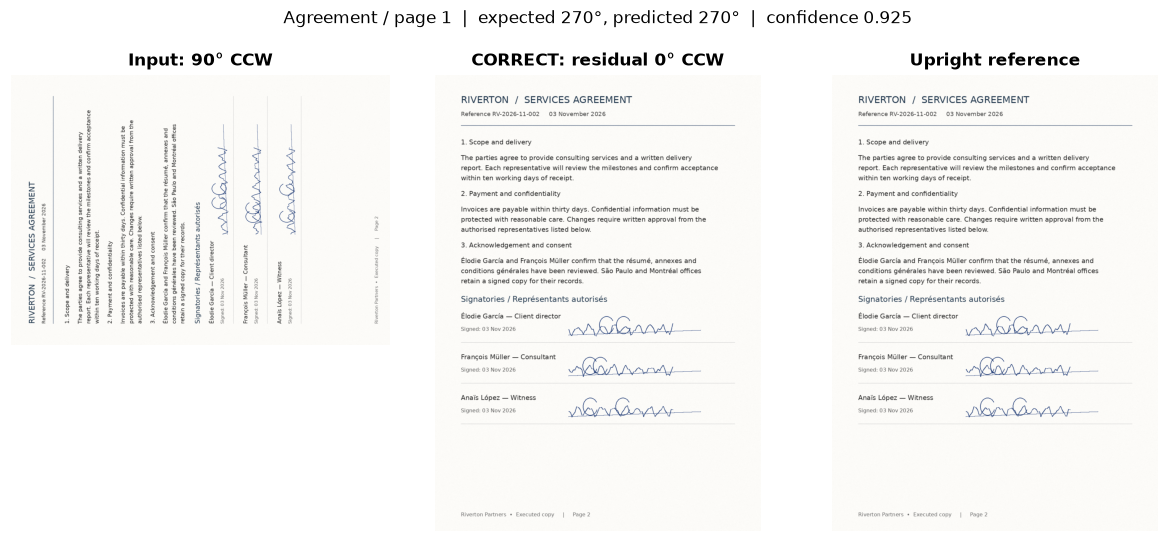

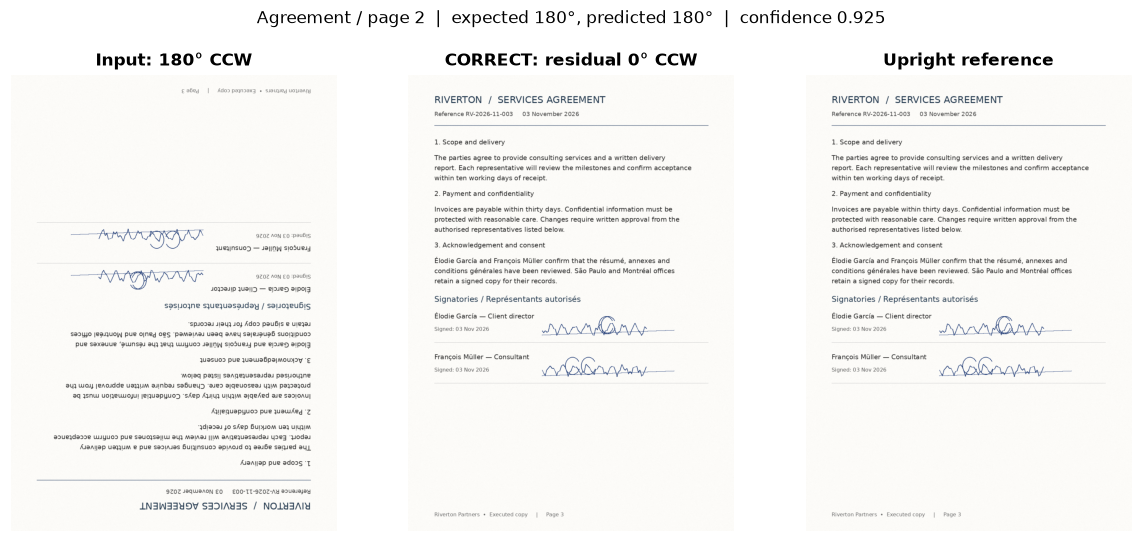

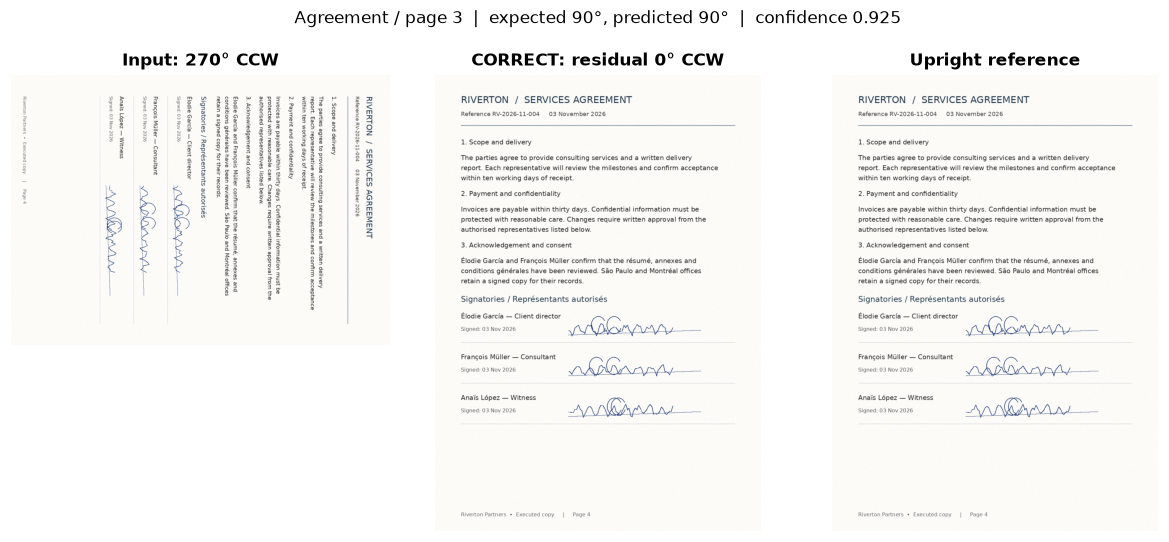

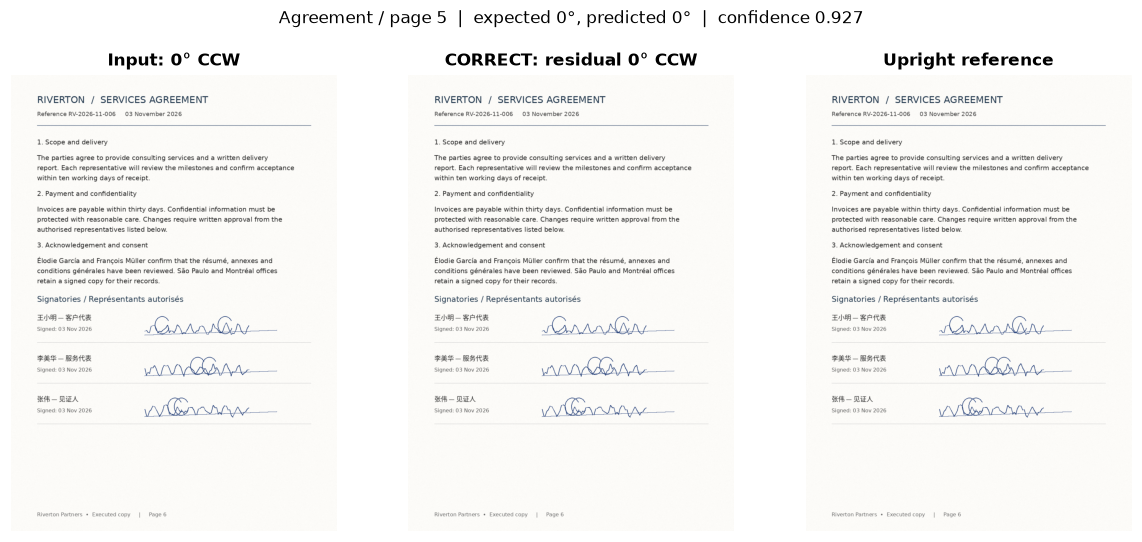

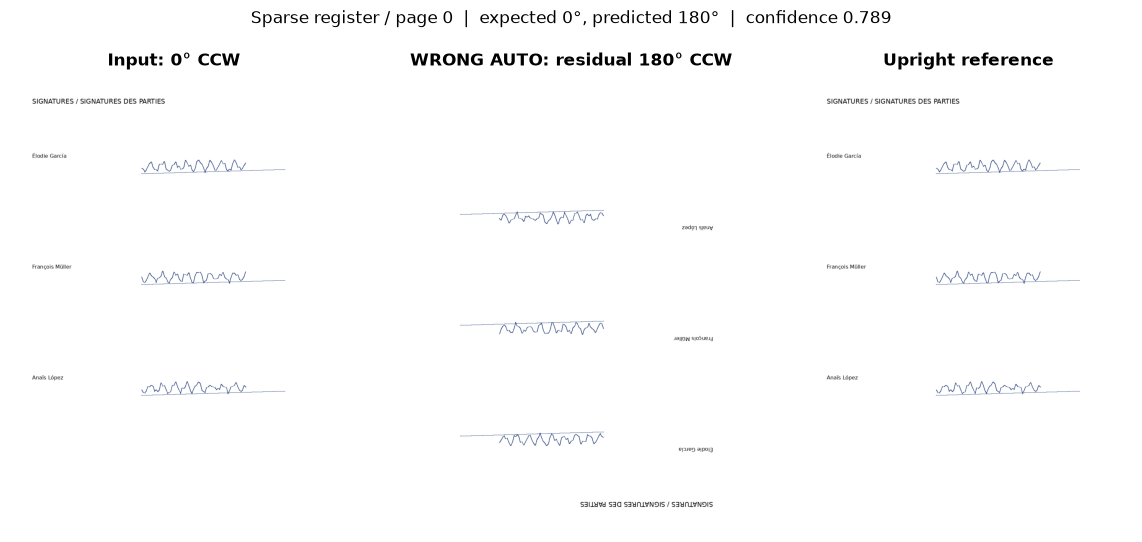

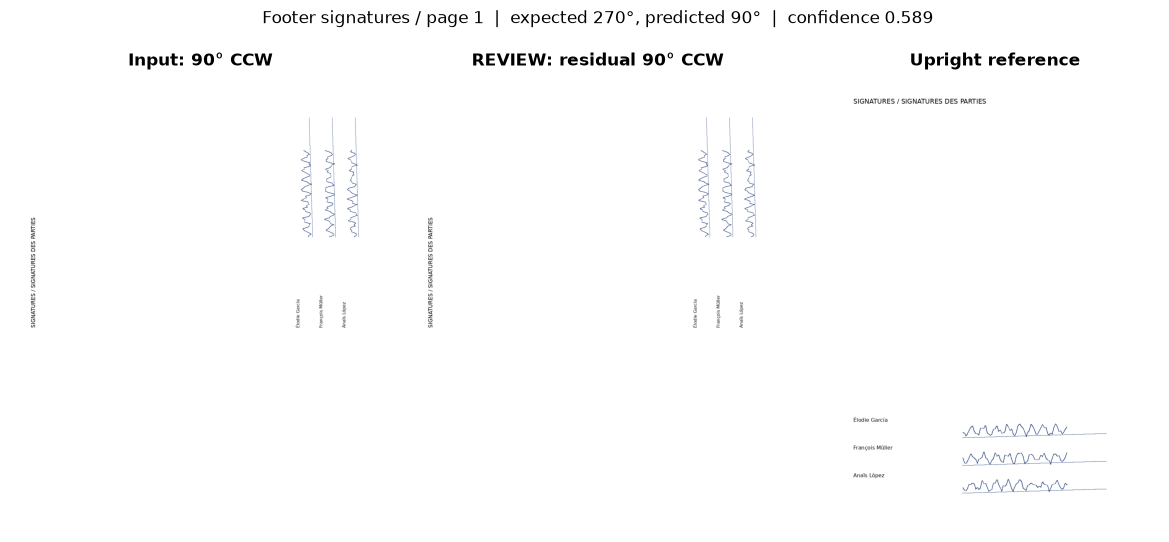

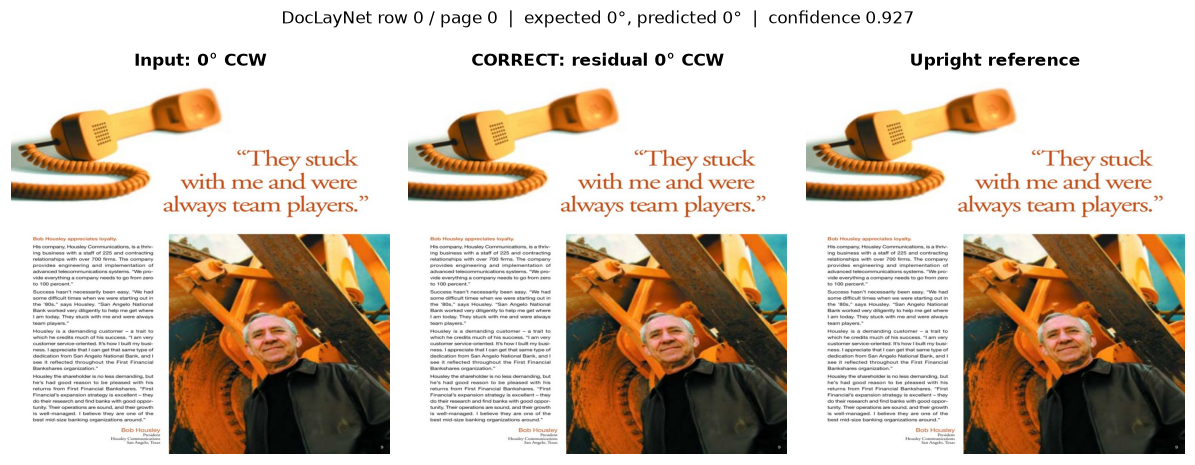

In [6]:
def show_case(key):
    row = results.loc[key]
    images = previews[key]
    state = "REVIEW" if row.review else ("CORRECT" if row.final_upright else "WRONG AUTO")
    fig, axes = plt.subplots(1, 3, figsize=(11, 5))
    titles = [f"Input: {row.ccw}° CCW", f"{state}: residual {row.residual}° CCW", "Upright reference"]
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=11)
        ax.axis("off")
        ax.set_anchor("N")
    fig.suptitle(f"{row.document} / page {row.page}  |  expected {row.expected}°, predicted {row.predicted}°"
                 f"  |  confidence {row.confidence:.3f}", fontsize=11)
    plt.tight_layout()
    plt.show()

selected = results.index[(results.document == "Agreement") & results.ccw.isin([90, 180, 270])].tolist()[:3]
if len(references) == 6:
    selected.append(results.index[(results.document == "Agreement") & (results.page == 5)][0])
for mask in [results.wrong_auto, results.review & (results.ccw != 0), results.source == "public"]:
    candidates = results.index[mask]
    if len(candidates):
        selected.append(candidates[0])
for key in dict.fromkeys(selected):
    show_case(key)
if not results.wrong_auto.any():
    display(Markdown("No confident error reproduced on this run. Review all sparse pages; do not fabricate a failure."))

### Inspect every decision
Scores for both 0° and 180° help inspect reversal confusion. Confidence is a model softmax
score, not a calibrated probability that a page is correctly oriented. The failure condition
is measured against construction ground truth, independently of the model's confidence.

In [7]:
display(results[["id", "document", "page", "ccw", "expected", "predicted", "confidence",
                 "p0", "p180", "review", "wrong_auto", "final_upright"]].round(3))
assert int(summary.loc["Overall", "Pages"]) == len(results)
assert len(timing) == len(results) * REPEATS
assert (counts.sum(axis=1) == results.groupby("document", sort=False).size()).all()
assert np.isclose(summary.loc["Overall", "Final upright %"], 100 * results.final_upright.mean())
# A real error is displayed when present, never asserted as a model contract.
errors = results[~results.classifier_correct]
display(Markdown(f"**Observed:** {int(results.classifier_correct.sum())}/{len(results)} correct classifier labels; "
    f"{int(results.final_upright.sum())}/{len(results)} outputs upright; "
    f"{int(results.review.sum())} reviews; {int(results.wrong_auto.sum())} wrong automatic outputs. "
    f"Warm median **{timing.ms.median():.1f} ms**, P95 **{timing.ms.quantile(.95):.1f} ms**."))
if len(errors):
    error = errors.iloc[0]
    display(Markdown(f"First classification failure: **{error.document}, page {error.page}**, "
        f"expected {error.expected}°, predicted {error.predicted}°, confidence {error.confidence:.3f}."))

,id,document,page,ccw,expected,predicted,confidence,p0,p180,review,wrong_auto,final_upright
0,0,Agreement,0,0,0,0,0.926,0.926,0.025,False,False,True
1,1,Agreement,1,90,270,270,0.925,0.025,0.025,False,False,True
2,2,Agreement,2,180,180,180,0.925,0.025,0.925,False,False,True
3,3,Agreement,3,270,90,90,0.925,0.025,0.025,False,False,True
4,4,Agreement,4,180,180,180,0.924,0.025,0.924,False,False,True
5,5,Agreement,5,0,0,0,0.927,0.927,0.024,False,False,True
6,6,Sparse register,0,0,0,180,0.789,0.162,0.789,False,True,False
7,7,Sparse register,1,90,270,90,0.763,0.022,0.024,False,True,False
8,8,Sparse register,2,180,180,180,0.864,0.095,0.864,False,False,True
9,9,Sparse register,3,270,90,90,0.886,0.019,0.020,False,False,True


**Observed:** 18/22 correct classifier labels; 18/22 outputs upright; 3 reviews; 2 wrong automatic outputs. Warm median **36.7 ms**, P95 **115.4 ms**.

First classification failure: **Sparse register, page 0**, expected 0°, predicted 180°, confidence 0.789.

## Takeaways
- Inspect the wrong automatic outputs: the default confidence threshold cannot guarantee
  safety for signature-dominated pages. Sparse readable labels can disagree with the model.
- Review flags preserve input orientation; a rotated reviewed page remains rotated until
  a person corrects it. Final-upright rate alone hides this workload.
- Printed agreements and public report pages are useful controls, but not substitutes for
  a held-out collection of real scanned signatory documents. Do not tune a production
  threshold or claim a general accuracy rate from these selected cases.
- Public samples and their license/provenance are in `data/doclaynet/`. Generated PDFs,
  per-page decisions, and all timed calls are in ignored `validation_data/` for local audit.
  Rerun on the deployment CPU to measure its latency; PDF I/O and cold startup add cost.